RAILPULSE AI — MODEL EXPLAINABILITY
Internal training trains: 2012
Validation trains: 504
Reserved final-test trains: 630

Loading data in chunks...
Processed 300,000 rows
Processed 600,000 rows
Processed 900,000 rows

DATA LOADED
Training shape: (699293, 9)
Validation shape: (171336, 9)

Training Delta Learning model...
Model training completed in 10.75 seconds.

Validation sample size: 30000

Baseline validation MAE: 9.0944

Calculating permutation importance...
Repeats per feature: 3

Processing feature: current_arr_delay
Mean MAE increase: 38.2070

Processing feature: distance_to_next
Mean MAE increase: 0.1644

Processing feature: current_distance
Mean MAE increase: 0.1044

Processing feature: current_sequence
Mean MAE increase: 0.0483

Processing feature: arrival_hour_sin
Mean MAE increase: 0.0058

Processing feature: arrival_hour_cos
Mean MAE increase: 0.0022

Processing feature: day_of_week_sin
Mean MAE increase: 0.0000

Processing feature: day_of_week_cos
Mean MAE increase: 0.0

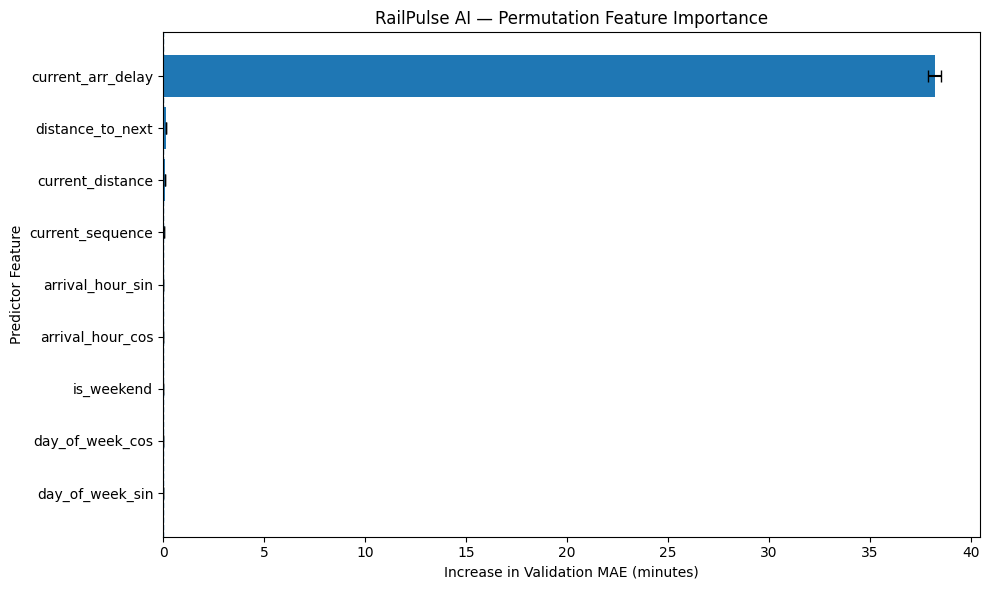


Figure saved: ../outputs/figures\05_permutation_feature_importance.png

EXPLAINABILITY ANALYSIS COMPLETED
Baseline validation MAE: 9.0944
Most important feature: current_arr_delay
Least important feature: is_weekend

Remember:
Positive importance = shuffling increased prediction error.
Negative importance = shuffling reduced prediction error.
Correlated predictors can share or mask importance.


4618

In [1]:

# ============================================================
# RAILPULSE AI — MODEL EXPLAINABILITY
# Permutation Feature Importance for Delta Learning
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_PATH = "../data/processed/railpulse_model_features.csv"

MANIFEST_PATH = (
    "../outputs/tables/three_way_train_split_manifest.csv"
)

OUTPUT_DIR = "../outputs/tables"
FIGURE_DIR = "../outputs/figures"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

CHUNK_SIZE = 100_000
RANDOM_STATE = 42

VALIDATION_SAMPLE_SIZE = 30_000
N_REPEATS = 3

FEATURE_COLS = [
    "current_arr_delay",
    "distance_to_next",
    "current_distance",
    "current_sequence",
    "arrival_hour_sin",
    "arrival_hour_cos",
    "day_of_week_sin",
    "day_of_week_cos",
    "is_weekend"
]

TARGET_COL = "next_arr_delay"

USE_COLS = (
    ["train"] + FEATURE_COLS + [TARGET_COL]
)

# ------------------------------------------------------------
# 2. LOAD THREE-WAY SPLIT MANIFEST
# ------------------------------------------------------------

print("=" * 70)
print("RAILPULSE AI — MODEL EXPLAINABILITY")
print("=" * 70)

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={"train": str}
)

train_ids = set(
    manifest.loc[
        manifest["split"] == "internal_train",
        "train"
    ]
)

validation_ids = set(
    manifest.loc[
        manifest["split"] == "validation",
        "train"
    ]
)

final_test_ids = set(
    manifest.loc[
        manifest["split"] == "reserved_final_test",
        "train"
    ]
)

assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(final_test_ids)
assert validation_ids.isdisjoint(final_test_ids)

print("Internal training trains:", len(train_ids))
print("Validation trains:", len(validation_ids))
print("Reserved final-test trains:", len(final_test_ids))

# ------------------------------------------------------------
# 3. LOAD INTERNAL TRAINING DATA IN CHUNKS
# ------------------------------------------------------------

X_train_parts = []
y_train_parts = []

X_val_parts = []
y_val_parts = []

total_rows = 0

print("\nLoading data in chunks...")

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=USE_COLS,
    dtype={"train": str},
    chunksize=CHUNK_SIZE
):

    total_rows += len(chunk)

    train_mask = chunk["train"].isin(
        train_ids
    ).to_numpy()

    val_mask = chunk["train"].isin(
        validation_ids
    ).to_numpy()

    X = chunk[FEATURE_COLS].to_numpy(
        dtype=np.float32
    )

    y = chunk[TARGET_COL].to_numpy(
        dtype=np.float32
    )

    if train_mask.any():
        X_train_parts.append(X[train_mask])
        y_train_parts.append(y[train_mask])

    if val_mask.any():
        X_val_parts.append(X[val_mask])
        y_val_parts.append(y[val_mask])

    if total_rows % 300_000 < CHUNK_SIZE:
        print(f"Processed {total_rows:,} rows")

X_train = np.concatenate(X_train_parts)
y_train = np.concatenate(y_train_parts)

X_val = np.concatenate(X_val_parts)
y_val = np.concatenate(y_val_parts)

del X_train_parts, y_train_parts
del X_val_parts, y_val_parts
gc.collect()

print("\nDATA LOADED")
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

# ------------------------------------------------------------
# 4. TRAIN DELTA LEARNING MODEL
# ------------------------------------------------------------

delay_index = FEATURE_COLS.index(
    "current_arr_delay"
)

current_train_delay = X_train[:, delay_index]

delta_target = (
    y_train - current_train_delay
).astype(np.float32)

delta_model = HistGradientBoostingRegressor(
    loss="absolute_error",
    learning_rate=0.06,
    max_iter=100,
    max_leaf_nodes=31,
    min_samples_leaf=40,
    l2_regularization=2.0,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=12,
    random_state=RANDOM_STATE
)

print("\nTraining Delta Learning model...")

start = time.time()

delta_model.fit(
    X_train,
    delta_target
)

training_time = time.time() - start

print(
    f"Model training completed in {training_time:.2f} seconds."
)

# ------------------------------------------------------------
# 5. SELECT VALIDATION SAMPLE
# ------------------------------------------------------------

rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(
    VALIDATION_SAMPLE_SIZE,
    len(X_val)
)

sample_indices = rng.choice(
    len(X_val),
    size=sample_size,
    replace=False
)

X_sample = X_val[sample_indices].copy()
y_sample = y_val[sample_indices].copy()

print("\nValidation sample size:", len(X_sample))

# ------------------------------------------------------------
# 6. DEFINE PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_next_delay(model, X):

    predicted_change = model.predict(X)

    current_delay = X[:, delay_index]

    predicted_next_delay = (
        current_delay + predicted_change
    )

    return np.maximum(
        predicted_next_delay,
        0
    )

# ------------------------------------------------------------
# 7. BASELINE VALIDATION ERROR
# ------------------------------------------------------------

baseline_predictions = predict_next_delay(
    delta_model,
    X_sample
)

baseline_mae = mean_absolute_error(
    y_sample,
    baseline_predictions
)

print("\nBaseline validation MAE:", round(baseline_mae, 4))

# ------------------------------------------------------------
# 8. PERMUTATION FEATURE IMPORTANCE
# ------------------------------------------------------------

print("\nCalculating permutation importance...")
print("Repeats per feature:", N_REPEATS)

importance_records = []

for feature_index, feature_name in enumerate(
    FEATURE_COLS
):

    print(f"\nProcessing feature: {feature_name}")

    repeat_importances = []

    for repeat in range(N_REPEATS):

        X_permuted = X_sample.copy()

        # Shuffle only the selected feature
        permutation = rng.permutation(
            len(X_permuted)
        )

        X_permuted[:, feature_index] = (
            X_permuted[permutation, feature_index]
        )

        permuted_predictions = predict_next_delay(
            delta_model,
            X_permuted
        )

        permuted_mae = mean_absolute_error(
            y_sample,
            permuted_predictions
        )

        importance = (
            permuted_mae - baseline_mae
        )

        repeat_importances.append(importance)

        del X_permuted, permuted_predictions
        gc.collect()

    importance_records.append({
        "Feature": feature_name,
        "Importance_Mean": np.mean(repeat_importances),
        "Importance_Std": np.std(
            repeat_importances,
            ddof=1
        ),
        "Repeat_1": repeat_importances[0],
        "Repeat_2": repeat_importances[1],
        "Repeat_3": repeat_importances[2]
    })

    print(
        f"Mean MAE increase: "
        f"{np.mean(repeat_importances):.4f}"
    )

# ------------------------------------------------------------
# 9. RANK FEATURES
# ------------------------------------------------------------

importance_df = pd.DataFrame(
    importance_records
)

importance_df = importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 75)

print(
    importance_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. SAVE FEATURE IMPORTANCE TABLE
# ------------------------------------------------------------

importance_path = os.path.join(
    OUTPUT_DIR,
    "permutation_feature_importance.csv"
)

importance_df.to_csv(
    importance_path,
    index=False
)

print("\nSaved:", importance_path)

# ------------------------------------------------------------
# 11. CREATE FEATURE IMPORTANCE VISUALIZATION
# ------------------------------------------------------------

plot_df = importance_df.sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_Std"],
    capsize=4
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Increase in Validation MAE (minutes)"
)

plt.ylabel("Predictor Feature")

plt.title(
    "RailPulse AI — Permutation Feature Importance"
)

plt.tight_layout()

figure_path = os.path.join(
    FIGURE_DIR,
    "05_permutation_feature_importance.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved:", figure_path)

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXPLAINABILITY ANALYSIS COMPLETED")
print("=" * 70)

print("Baseline validation MAE:", round(baseline_mae, 4))

print(
    "Most important feature:",
    importance_df.iloc[0]["Feature"]
)

print(
    "Least important feature:",
    importance_df.iloc[-1]["Feature"]
)

print("\nRemember:")
print("Positive importance = shuffling increased prediction error.")
print("Negative importance = shuffling reduced prediction error.")
print("Correlated predictors can share or mask importance.")

# Release temporary arrays
del X_train, y_train, X_val, y_val
del X_sample, y_sample, baseline_predictions
del delta_target, delta_model
gc.collect()
